
# Email Spam Detection Using Machine Learning

## 1. Project Overview

The objective of this project is to develop a machine learning system that classifies text messages as either **Spam** or **Ham (Legitimate)**.

The project uses the SMS Spam Collection dataset recommended by the Oasis Infobyte internship task. Although the task is titled Email Spam Detection, the selected dataset contains SMS messages. This distinction is documented for transparency.

## 2. Project Objectives

- Explore and understand the dataset.
- Analyse the distribution of spam and legitimate messages.
- Clean and preprocess text data.
- Convert text into numerical features using TF-IDF.
- Train and compare multiple machine learning classifiers.
- Evaluate models using accuracy, precision, recall, F1-score, and a confusion matrix.
- Visualise frequently occurring words in spam and legitimate messages.

## 3. Dataset Information

**Dataset:** SMS Spam Collection  
**Source:** UCI Machine Learning Repository  
**File:** `SMSSpamCollection`  
**Target variable:** `label`  
**Message column:** `message`

The dataset contains two classes:

- `ham`: Legitimate messages.
- `spam`: Unwanted or promotional messages.

## 4. Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- NLTK / Regular Expressions
- WordCloud
- Jupyter Notebook


In [1]:

# 1. Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# Set visualisation style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

# 2. Load the SMS Spam Collection dataset

# Locate the dataset relative to the notebook's working directory
DATA_PATH = Path.cwd() / "data" / "raw" / "SMSSpamCollection"

# Load the tab-separated dataset
df = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")

# Display the first five records
display(df.head())


Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



## 5. Class Distribution Analysis

Before building a machine learning model, we need to understand how the target classes are distributed.

The dataset contains two categories:

- **Ham:** Legitimate messages.
- **Spam:** Unwanted messages.

We will calculate the number and percentage of messages in each category to identify whether the dataset is balanced or imbalanced.


In [3]:

# Count messages in each category
class_counts = df["label"].value_counts()

# Calculate class percentages
class_percentages = df["label"].value_counts(normalize=True) * 100

# Combine counts and percentages into a summary table
class_distribution = pd.DataFrame({
    "Message Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

display(class_distribution)

print(f"Total messages: {len(df)}")


,Message Count,Percentage (%)
label,,
ham,4825,86.59
spam,747,13.41


Total messages: 5572


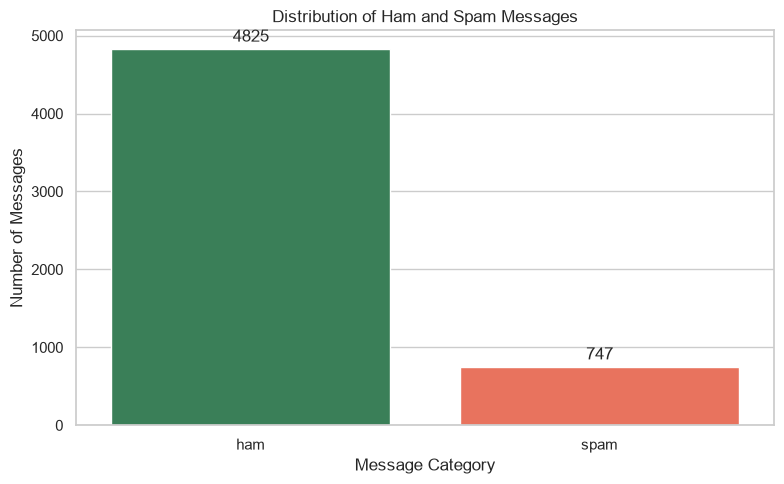

In [4]:

# Visualise class distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette={"ham": "seagreen", "spam": "tomato"},
    legend=False
)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

# Display count labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()



## 6. Text Preprocessing

Raw text data often contains uppercase letters, punctuation, unnecessary symbols, and common words that provide limited classification value.

We will apply the following preprocessing operations:

1. Convert text to lowercase.
2. Remove punctuation and special characters.
3. Remove stopwords (common words such as "the", "is", and "and").
4. Tokenise the messages.
5. Apply stemming to reduce words to their root forms.

These operations help standardise the text and prepare it for feature extraction.


In [5]:

# Import text preprocessing libraries

import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Download the English stopwords corpus
nltk.download("stopwords")

# Initialise stopwords and stemmer
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

print("Text preprocessing tools are ready.")


[nltk_data] Downloading package stopwords to C:\Users\VANSH
[nltk_data]     GANDHI\AppData\Roaming\nltk_data...


Text preprocessing tools are ready.


[nltk_data]   Unzipping corpora\stopwords.zip.


In [6]:

# Function to clean and preprocess text messages

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation, numbers, and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Split text into individual words
    words = text.split()

    # Remove stopwords and apply stemming
    cleaned_words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    # Join cleaned words back into a sentence
    return " ".join(cleaned_words)


# Apply preprocessing to the message column
df["cleaned_message"] = df["message"].apply(preprocess_text)

print("Text preprocessing completed successfully.")

# Compare original and cleaned messages
display(df[["message", "cleaned_message"]].head(10))


Text preprocessing completed successfully.


,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week word back like fun still...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request mell mell oru minnaminungint nurun...
8,WINNER!! As a valued network customer you have...,winner valu network custom select receivea pri...
9,Had your mobile 11 months or more? U R entitle...,mobil month u r entitl updat latest colour mob...



## 7. Message Length Analysis

Message length can provide useful information for spam detection.

Spam messages may contain promotional language, offers, links, and calls to action, while legitimate messages may be shorter and more conversational.

We will calculate the character length and word count of each message and compare their distributions across the two categories.


In [7]:

# Calculate message length and word count

df["message_length"] = df["message"].apply(len)
df["word_count"] = df["message"].apply(lambda x: len(x.split()))

# Display descriptive statistics by category
length_summary = df.groupby("label")[
    ["message_length", "word_count"]
].agg(["mean", "median", "max"])

display(length_summary.round(2))


message_length             word_count            
                mean median  max       mean median  max
label                                                  
ham            71.48   52.0  910      14.31   11.0  171
spam          138.67  149.0  223      23.91   25.0   35

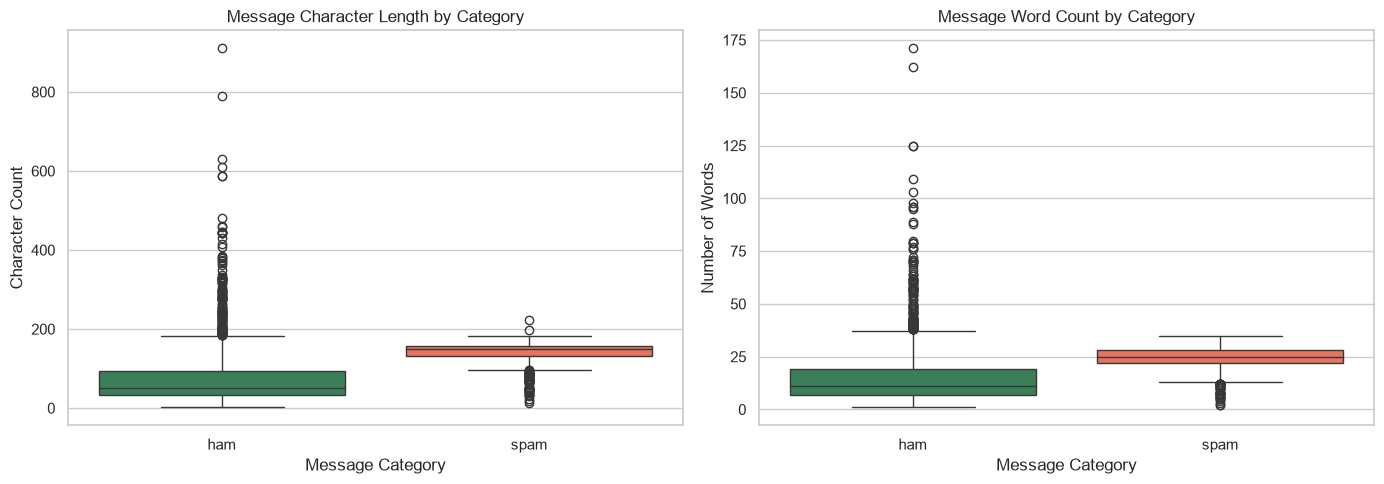

In [8]:

# Compare message lengths between ham and spam

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="label",
    y="message_length",
    hue="label",
    palette={"ham": "seagreen", "spam": "tomato"},
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Message Character Length by Category")
axes[0].set_xlabel("Message Category")
axes[0].set_ylabel("Character Count")

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    hue="label",
    palette={"ham": "seagreen", "spam": "tomato"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Message Word Count by Category")
axes[1].set_xlabel("Message Category")
axes[1].set_ylabel("Number of Words")

plt.tight_layout()
plt.show()



### Observations

- Spam messages generally contain more characters and words than legitimate messages.
- The median message length and word count are higher for spam messages.
- Legitimate messages contain several extreme outliers, indicating that some ham messages can also be unusually long.
- Although message length provides useful exploratory information, it cannot independently distinguish spam from legitimate messages.

Therefore, we will use text-based features to train our classification models.



## 8. Feature Extraction Using TF-IDF

Machine learning algorithms cannot directly understand raw text. Therefore, we need to convert messages into numerical representations.

We will use **TF-IDF (Term Frequency–Inverse Document Frequency)**.

TF-IDF measures how important a word is within a particular document relative to the entire collection of documents.

It consists of two components:

1. **Term Frequency (TF):** Measures how frequently a word appears in a document.
2. **Inverse Document Frequency (IDF):** Reduces the importance of words that appear in many documents and gives more weight to words that are relatively uncommon.

The TF-IDF score is calculated as:

TF-IDF = Term Frequency × Inverse Document Frequency

Words that are frequent in a particular message but uncommon across the overall dataset can receive higher scores.

We will use Scikit-learn's `TfidfVectorizer` to convert the cleaned messages into numerical feature vectors.


In [9]:

# Import TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialise TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Convert cleaned messages into numerical feature vectors
X = tfidf.fit_transform(df["cleaned_message"])

# Target variable
y = df["label"]

print("TF-IDF vectorization completed successfully.")
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)
print("Number of unique features:", len(tfidf.get_feature_names_out()))


TF-IDF vectorization completed successfully.
Feature matrix shape: (5572, 5000)
Target variable shape: (5572,)
Number of unique features: 5000


In [10]:

# Inspect the TF-IDF feature vocabulary

feature_names = tfidf.get_feature_names_out()

print("First 20 TF-IDF features:")
print(feature_names[:20])

# Convert a small sample into a readable DataFrame
sample_features = pd.DataFrame(
    X[:5].toarray(),
    columns=feature_names
)

display(sample_features.iloc[:, :15])


First 20 TF-IDF features:
['aah' 'aathi' 'aathi dear' 'aathi love' 'abi' 'abiola' 'abj' 'abl'
 'abl come' 'abl deliv' 'abl get' 'abt' 'abta' 'abta complimentari' 'ac'
 'acc' 'accept' 'accept brother' 'accept day' 'access']


,aah,aathi,aathi dear,aathi love,abi,abiola,abj,abl,abl come,abl deliv,abl get,abt,abta,abta complimentari,ac
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



## 9. Splitting the Dataset into Training and Testing Sets

Before training machine learning models, we divide the dataset into two subsets:

- **Training set (80%):** Used to train the machine learning models.
- **Testing set (20%):** Used to evaluate how well the trained models perform on unseen messages.

We use stratified sampling to preserve the original proportion of spam and ham messages in both subsets.

The TF-IDF vectorizer will be fitted only on the training messages to prevent data leakage.


In [11]:

# Import train_test_split
from sklearn.model_selection import train_test_split

# Separate input messages and target labels
X_text = df["cleaned_message"]
y = df["label"]

# Split the dataset into training and testing sets
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully.")
print(f"Training samples: {len(X_train_text)}")
print(f"Testing samples: {len(X_test_text)}")

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Dataset split completed successfully.
Training samples: 4457
Testing samples: 1115

Training class distribution:
label
ham     86.58
spam    13.42
Name: proportion, dtype: float64

Testing class distribution:
label
ham     86.64
spam    13.36
Name: proportion, dtype: float64


In [12]:

# Create a fresh TF-IDF vectorizer for model training

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Fit only on training data
X_train = tfidf.fit_transform(X_train_text)

# Transform testing data without fitting again
X_test = tfidf.transform(X_test_text)

print("Leakage-safe TF-IDF transformation completed.")
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)


Leakage-safe TF-IDF transformation completed.
Training feature matrix: (4457, 5000)
Testing feature matrix: (1115, 5000)



## 10. Model Training

We will train and compare two machine learning classification algorithms.

### 1. Multinomial Naive Bayes

Multinomial Naive Bayes is a probabilistic classification algorithm commonly used for text classification. It estimates the probability of a message belonging to a particular category based on its features.

### 2. Logistic Regression

Logistic Regression is a supervised classification algorithm that estimates the probability of a message belonging to a particular class.

Both models will be trained using the TF-IDF feature matrix and evaluated on the same unseen testing dataset.


In [13]:

# Import machine learning classifiers

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Initialise the classifiers
nb_model = MultinomialNB()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Machine learning models initialised successfully.")


Machine learning models initialised successfully.


In [14]:

# Train Multinomial Naive Bayes
nb_model.fit(X_train, y_train)

# Train Logistic Regression
lr_model.fit(X_train, y_train)

print("Both models trained successfully.")

print("\nModel training summary:")
print("1. Multinomial Naive Bayes - Trained")
print("2. Logistic Regression - Trained")


Both models trained successfully.

Model training summary:
1. Multinomial Naive Bayes - Trained
2. Logistic Regression - Trained



## 11. Model Evaluation

After training the classifiers, we evaluate their performance using the testing dataset.

We use the following evaluation metrics:

1. **Accuracy:** Percentage of all predictions that are correct.
2. **Precision:** Of all messages predicted as spam, how many were actually spam?
3. **Recall:** Of all actual spam messages, how many did the model successfully identify?
4. **F1-score:** Harmonic mean of precision and recall.
5. **Confusion Matrix:** Shows correct and incorrect predictions for each class.

For spam detection, recall is particularly important because failing to identify spam allows unwanted messages to be classified as legitimate.

We will compare both models using the same testing dataset.


In [15]:

# Generate predictions using both trained models

y_pred_nb = nb_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test)

print("Predictions generated successfully.")
print("Naive Bayes predictions:", len(y_pred_nb))
print("Logistic Regression predictions:", len(y_pred_lr))


Predictions generated successfully.
Naive Bayes predictions: 1115
Logistic Regression predictions: 1115


In [16]:

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Function to calculate evaluation metrics
def evaluate_model(y_true, y_pred, model_name):

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label="spam"
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label="spam"
        ),
        "F1-Score": f1_score(
            y_true, y_pred, pos_label="spam"
        )
    }

    return metrics


# Evaluate both models
nb_metrics = evaluate_model(
    y_test, y_pred_nb, "Multinomial Naive Bayes"
)

lr_metrics = evaluate_model(
    y_test, y_pred_lr, "Logistic Regression"
)

# Create comparison table
model_comparison = pd.DataFrame([
    nb_metrics,
    lr_metrics
])

display(
    model_comparison.set_index("Model").round(4)
)


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Multinomial Naive Bayes,0.9731,1.0,0.7987,0.8881
Logistic Regression,0.9722,1.0,0.7919,0.8839


In [17]:

# Detailed classification report for Naive Bayes

print("MULTINOMIAL NAIVE BAYES")
print(classification_report(y_test, y_pred_nb))


# Detailed classification report for Logistic Regression

print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))


MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.80      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115

LOGISTIC REGRESSION
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115




## 12. Confusion Matrix Analysis

A confusion matrix provides a detailed breakdown of correct and incorrect predictions.

It contains four outcomes:

- **True Positive (TP):** Spam correctly classified as spam.
- **True Negative (TN):** Ham correctly classified as ham.
- **False Positive (FP):** Ham incorrectly classified as spam.
- **False Negative (FN):** Spam incorrectly classified as ham.

We will compare the confusion matrices of both classifiers to understand their classification errors.


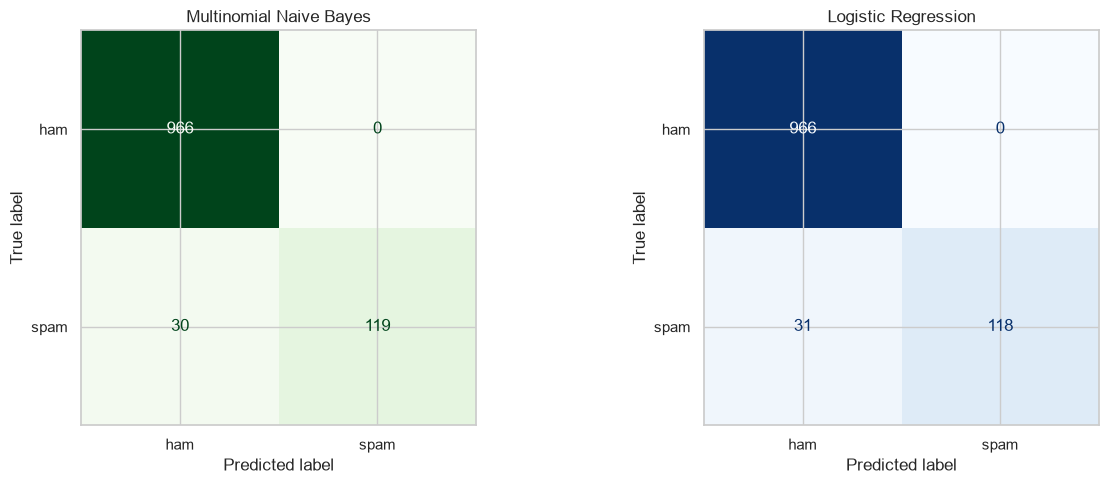

Naive Bayes Confusion Matrix:
[[966   0]
 [ 30 119]]

Logistic Regression Confusion Matrix:
[[966   0]
 [ 31 118]]


In [18]:

# Import confusion matrix utilities
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Define class order
labels = ["ham", "spam"]

# Calculate confusion matrices
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=labels)
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=labels)

# Display both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

disp_nb = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=labels
)
disp_nb.plot(
    ax=axes[0],
    cmap="Greens",
    colorbar=False
)
axes[0].set_title("Multinomial Naive Bayes")

disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=labels
)
disp_lr.plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)
axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()

print("Naive Bayes Confusion Matrix:")
print(cm_nb)

print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)



### Why Is Recall Particularly Important for Spam Detection?

Recall measures the proportion of actual spam messages that are successfully identified by the model.

In spam detection, low recall means that unwanted messages may pass through the filtering system and reach the user's inbox.

False negatives are particularly undesirable because they represent spam messages incorrectly classified as legitimate.

Although high precision helps prevent legitimate messages from being incorrectly marked as spam, recall is important for reducing the number of spam messages that escape detection.

In this experiment, Multinomial Naive Bayes achieved a spam recall of approximately 79.87%, meaning it identified around 80% of actual spam messages while missing approximately 20%.

Therefore, improving recall while maintaining acceptable precision is an important objective for a practical spam detection system.



## 13. WordCloud Visualisation

A WordCloud represents frequently occurring words using different font sizes.

Words that appear more frequently are displayed in larger sizes.

We will generate separate WordCloud visualisations for:

1. Spam messages.
2. Legitimate (ham) messages.

This helps identify common vocabulary patterns and differences between the two categories.


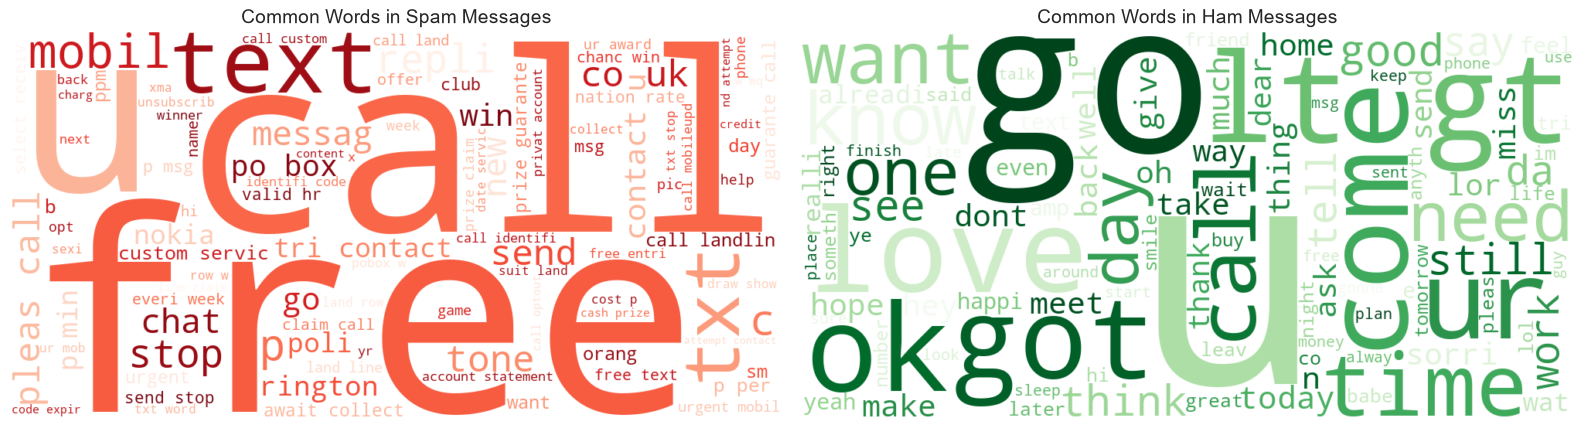

In [19]:

# Import WordCloud
from wordcloud import WordCloud

# Combine cleaned messages by category
spam_text = " ".join(
    df.loc[df["label"] == "spam", "cleaned_message"]
)

ham_text = " ".join(
    df.loc[df["label"] == "ham", "cleaned_message"]
)

# Generate WordClouds
spam_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="Reds",
    max_words=100
).generate(spam_text)

ham_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="Greens",
    max_words=100
).generate(ham_text)

# Display both WordClouds
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(spam_wordcloud, interpolation="bilinear")
axes[0].set_title("Common Words in Spam Messages", fontsize=14)
axes[0].axis("off")

axes[1].imshow(ham_wordcloud, interpolation="bilinear")
axes[1].set_title("Common Words in Ham Messages", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()



### WordCloud Observations

The spam WordCloud contains prominent promotional terms such as "free", "call", "text", "mobile", "claim", and "reply". These words are commonly associated with advertisements, promotional offers, and unsolicited messages.

The ham WordCloud contains conversational terms such as "get", "go", "got", "come", "know", "love", and "time", reflecting everyday communication.

These differences demonstrate that spam and legitimate messages have distinct vocabulary patterns. WordCloud visualisation provides an intuitive way to explore these differences.



## 14. Final Model Comparison and Conclusion

### Model Performance Summary

Two machine learning classifiers were trained and evaluated using an 80:20 stratified train-test split.

| Evaluation Metric | Multinomial Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 97.31% | 97.22% |
| Spam Precision | 100.00% | 100.00% |
| Spam Recall | 79.87% | 79.19% |
| Spam F1-score | 88.81% | 88.39% |

### Selected Model

Multinomial Naive Bayes achieved slightly better performance across all four evaluation metrics.

Its confusion matrix showed:

- 966 legitimate messages correctly classified.
- 119 spam messages correctly detected.
- 30 spam messages incorrectly classified as legitimate.
- 0 legitimate messages incorrectly classified as spam.

Therefore, Multinomial Naive Bayes is selected as the best-performing model in this experiment.

### Conclusion

This project demonstrated how machine learning and natural language processing can be used to classify spam and legitimate messages.

The workflow included dataset exploration, text preprocessing, TF-IDF feature extraction, model training, evaluation, confusion matrix analysis, and WordCloud visualisation.

Multinomial Naive Bayes achieved 97.31% accuracy and 79.87% spam recall on the test dataset.

Although the results are promising, further improvements could focus on increasing spam recall while maintaining high precision.

**Dataset limitation:** The experiment uses the SMS Spam Collection dataset recommended by the internship task. Therefore, the results demonstrate SMS spam classification rather than direct evaluation on email messages.
